# Cooperation Through Simple Rules
## Iterated Prisoner’s Dilemma — IE49A Collective Computation

**Purpose:** investigate when simple repeated-interaction rules sustain cooperation, how errors disrupt it, and when forgiveness helps. This notebook includes executable code, saved outputs, figures, comparisons, and interpretations for use in a separately written report. It does **not** generate a report.

**Main question:** can reciprocity protect cooperators from exploitation while sustaining mutually beneficial interaction? A fixed-strategy tournament demonstrates the consequences of behavioral rules; it does not simulate strategies evolving.

## 1. How to run and reproduce

Use Python **3.11 or newer** (Python 3.12 recommended). In the activated `ie49a` environment, install `numpy`, `matplotlib`, `jupyterlab`, `ipykernel`, and `ipywidgets`, then run `python -m jupyter lab`. Open this notebook, select the environment’s Python kernel, and use **Restart Kernel and Run All Cells**.

The notebook is **self-contained**: it does not import `simulation.py`, read precomputed experiment files, or require ReportLab. The configuration cell below controls the main experiments. Figures and tables are regenerated in `notebook_results/`, relative to the current working directory. No input files are overwritten. Saved outputs can also be viewed on GitHub without running the notebook.

A fixed number of rounds is used, satisfying the assignment’s choice between a fixed horizon and a continuation probability. Players follow their rules without anticipating the final round.

In [1]:
%matplotlib inline
from pathlib import Path
import csv
import random
import sys
from dataclasses import dataclass
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
from html import escape

OUT = Path('notebook_results')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
COLORS = ['#009988', '#CC3311', '#0077BB', '#AA4499', '#EE9933']

def show_table(headers, rows, filename=None):
    rows = list(rows)
    if filename:
        with (OUT / filename).open('w', newline='') as f:
            writer = csv.writer(f)
            writer.writerow(headers)
            writer.writerows(rows)
    html = '<table><thead><tr>' + ''.join('<th>' + escape(str(x)) + '</th>' for x in headers) + '</tr></thead><tbody>'
    html += ''.join('<tr>' + ''.join('<td>' + escape(str(x)) + '</td>' for x in row) + '</tr>' for row in rows)
    display(HTML(html + '</tbody></table>'))

def finish(fig, filename):
    fig.savefig(OUT / filename, bbox_inches='tight')
    plt.show()
    plt.close(fig)

print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__, '| Matplotlib:', matplotlib.__version__)
print('Outputs:', OUT.resolve())

Python: 3.12.11
NumPy: 2.3.5 | Matplotlib: 3.10.8
Outputs: /Users/busenazkocali/IE49A/notebook_results


## 2. Payoff matrix and configurable experiment settings

`C` means cooperate and `D` means defect. Payoffs are shown as **(row player, column player)**. The ordering $T>R>P>S$ makes defection individually attractive in a one-shot encounter. The additional condition $2R>T+S$ ensures that mutual cooperation gives a greater total reward than alternating unilateral exploitation.

For the canonical matrix, mutual cooperation gives 6 total units per round, compared with 2 under mutual defection. This is the collective benefit that repeated interaction may preserve.

In [2]:
ROUNDS = 200
REPEATS = 30
SEED = 42
NOISE = 0.05
GENEROSITY = 0.10
T, R, P, S = 5, 3, 1, 0
assert ROUNDS >= 1 and REPEATS >= 2
assert 0 <= NOISE <= 1 and 0 <= GENEROSITY <= 1
show_table(['Your action / opponent action', 'C', 'D'],
           [['C', f'({R}, {R})', f'({S}, {T})'],
            ['D', f'({T}, {S})', f'({P}, {P})']], 'payoff_matrix.csv')
print(f'{ROUNDS} rounds, {REPEATS} repetitions, seed {SEED}; noise={NOISE}, generosity={GENEROSITY}')

Your action / opponent action,C,D
C,"(3, 3)","(0, 5)"
D,"(5, 0)","(1, 1)"


200 rounds, 30 repetitions, seed 42; noise=0.05, generosity=0.1


## 3. Strategy rules and modeling assumptions

| Strategy | Decision rule |
|---|---|
| ALL-C | Always cooperate. |
| ALL-D | Always defect. |
| TFT | Cooperate first; then copy the opponent’s previous executed action. |
| GRIM | Cooperate until any observed opponent defection; then defect forever. |
| GTFT | Cooperate first and after opponent cooperation; after opponent defection, cooperate with probability `GENEROSITY`. |

**Simultaneity:** both players decide from previous history before either current move is recorded. **Noise:** each intended action is flipped independently with probability $\epsilon$; executed actions are observed without error. Thus a mistake can trigger retaliation. **Memory:** histories reset between matches, and GRIM remembers any earlier defection. GTFT forgiveness is a new random draw each time it responds to defection.

**Round robin:** every distinct unordered pair plays once per repetition (10 pairs for five strategies), excluding self-play. Each strategy therefore faces four opponents with equal weight. Separate illustrative pair experiments may include self-pairs. There is no learning, selection, population change, spatial structure, or communication.

In [3]:
STRATEGIES = ('ALL-C', 'ALL-D', 'TFT', 'GRIM', 'GTFT')

@dataclass(frozen=True)
class Payoffs:
    T: float = 5
    R: float = 3
    P: float = 1
    S: float = 0

    def __post_init__(self):
        if not all(np.isfinite(x) for x in (self.T, self.R, self.P, self.S)):
            raise ValueError('Payoffs must be finite.')
        if not self.T > self.R > self.P > self.S:
            raise ValueError('Prisoner\'s Dilemma requires T > R > P > S.')
        if not 2 * self.R > self.T + self.S:
            raise ValueError('Use 2R > T + S so mutual cooperation beats alternation.')

    def score(self, a, b):
        return {(True, True): (self.R, self.R),
                (True, False): (self.S, self.T),
                (False, True): (self.T, self.S),
                (False, False): (self.P, self.P)}[a, b]


def choose(strategy, opponent_history, rng, generosity=.1):
    """True = cooperate. History contains observed, executed opponent moves."""
    if strategy not in STRATEGIES:
        raise ValueError(f'Unknown strategy: {strategy}')
    if strategy == 'ALL-C':
        return True
    if strategy == 'ALL-D':
        return False
    if not opponent_history:
        return True
    if strategy == 'GRIM':
        return all(opponent_history)
    if opponent_history[-1]:
        return True
    return strategy == 'GTFT' and rng.random() < generosity


def play(a, b, rounds=200, noise=0., generosity=.1, payoffs=None, seed=42):
    if a not in STRATEGIES or b not in STRATEGIES:
        raise ValueError('Unknown strategy.')
    if rounds < 1 or not 0 <= noise <= 1 or not 0 <= generosity <= 1:
        raise ValueError('Rounds must be positive; probabilities must be in [0,1].')
    rng = random.Random(seed)
    payoffs = payoffs or Payoffs()
    histories = [[], []]
    scores = np.zeros((rounds, 2))
    actions = np.zeros((rounds, 2), dtype=bool)
    for t in range(rounds):
        # Both decisions use histories from BEFORE this round.
        first = choose(a, histories[1], rng, generosity)
        second = choose(b, histories[0], rng, generosity)
        first ^= rng.random() < noise
        second ^= rng.random() < noise
        histories[0].append(first)
        histories[1].append(second)
        actions[t] = first, second
        scores[t] = payoffs.score(first, second)
    return scores, actions


def tournament(rounds=200, repeats=30, noise=0., generosity=.1, payoffs=None,
               seed=42, strategies=STRATEGIES):
    """Each unordered pair plays; self-play excluded. Equal encounter weights."""
    if repeats < 1 or len(strategies) < 2 or len(set(strategies)) != len(strategies):
        raise ValueError('Need positive repeats and at least two distinct strategies.')
    rng = random.Random(seed)
    n = len(strategies)
    scores = np.zeros((repeats, rounds, n))
    cooperation = np.zeros((repeats, rounds))
    matrix = np.full((n, n), np.nan)
    pairs = n * (n - 1) // 2
    for i in range(n):
        for j in range(i + 1, n):
            pair_scores = []
            for r in range(repeats):
                s, a = play(strategies[i], strategies[j], rounds, noise,
                            generosity, payoffs, rng.getrandbits(64))
                scores[r, :, i] += s[:, 0]
                scores[r, :, j] += s[:, 1]
                cooperation[r] += a.mean(axis=1) / pairs
                pair_scores.append(s.mean(axis=0))
            matrix[i, j], matrix[j, i] = np.mean(pair_scores, axis=0)
    # Payoff per encounter: divide by the number of opponents per strategy.
    scores /= n - 1
    return scores, cooperation, matrix


PAYOFFS = Payoffs(T, R, P, S)
print("Simulation functions ready:", ", ".join(STRATEGIES))

Simulation functions ready: ALL-C, ALL-D, TFT, GRIM, GTFT


## 4. Verify the implementation before interpreting results

These numerical checks test the payoff matrix, simultaneous TFT retaliation, persistent GRIM memory, forgiveness extremes, and seed reproducibility. They provide known-answer checks rather than treating attractive-looking graphs as proof of correctness.

In [4]:
canonical = Payoffs()
assert canonical.score(True, True) == (3, 3)
assert canonical.score(True, False) == (0, 5)
assert canonical.score(False, True) == (5, 0)
assert canonical.score(False, False) == (1, 1)
s, a = play('TFT', 'TFT', rounds=10)
assert a.all() and np.array_equal(s.sum(axis=0), [30, 30])
s, a = play('TFT', 'ALL-D', rounds=10)
assert np.array_equal(a[:, 0], [True] + [False] * 9)
assert np.array_equal(s.sum(axis=0), [9, 14])
assert not choose('GRIM', [True, False, True], random.Random(0))
assert choose('TFT', [True, False, True], random.Random(0))
assert not choose('GTFT', [False], random.Random(0), 0)
assert choose('GTFT', [False], random.Random(0), 1)
x = play('GTFT', 'TFT', noise=.05, seed=SEED)
y = play('GTFT', 'TFT', noise=.05, seed=SEED)
assert np.array_equal(x[0], y[0]) and np.array_equal(x[1], y[1])
s, c, m = tournament(rounds=10, repeats=1, strategies=('ALL-C', 'ALL-D'))
assert np.allclose(s[0, :, 0], 0) and np.allclose(s[0, :, 1], 5)
assert np.allclose(c, .5) and m[0, 1] == 0 and m[1, 0] == 5
print('All implementation checks passed.')

All implementation checks passed.


## 5. Pairwise experiments: reciprocity versus exploitation

Compare four deterministic encounters without action noise. Pair totals are **per player**, with no opponent normalization. TFT–TFT represents sustained reciprocal cooperation, ALL-D–ALL-D provides the mutual-defection benchmark, ALL-C–ALL-D illustrates exploitation, and TFT–ALL-D shows retaliation limiting exploitation.

A,B,Cooperation,Mean payoff A,Mean payoff B,Total A,Total B
TFT,TFT,100.00%,3.000,3.000,600.00,600.00
ALL-D,ALL-D,0.00%,1.000,1.000,200.00,200.00
ALL-C,ALL-D,50.00%,0.000,5.000,0.00,1000.00
TFT,ALL-D,0.25%,0.995,1.020,199.00,204.00


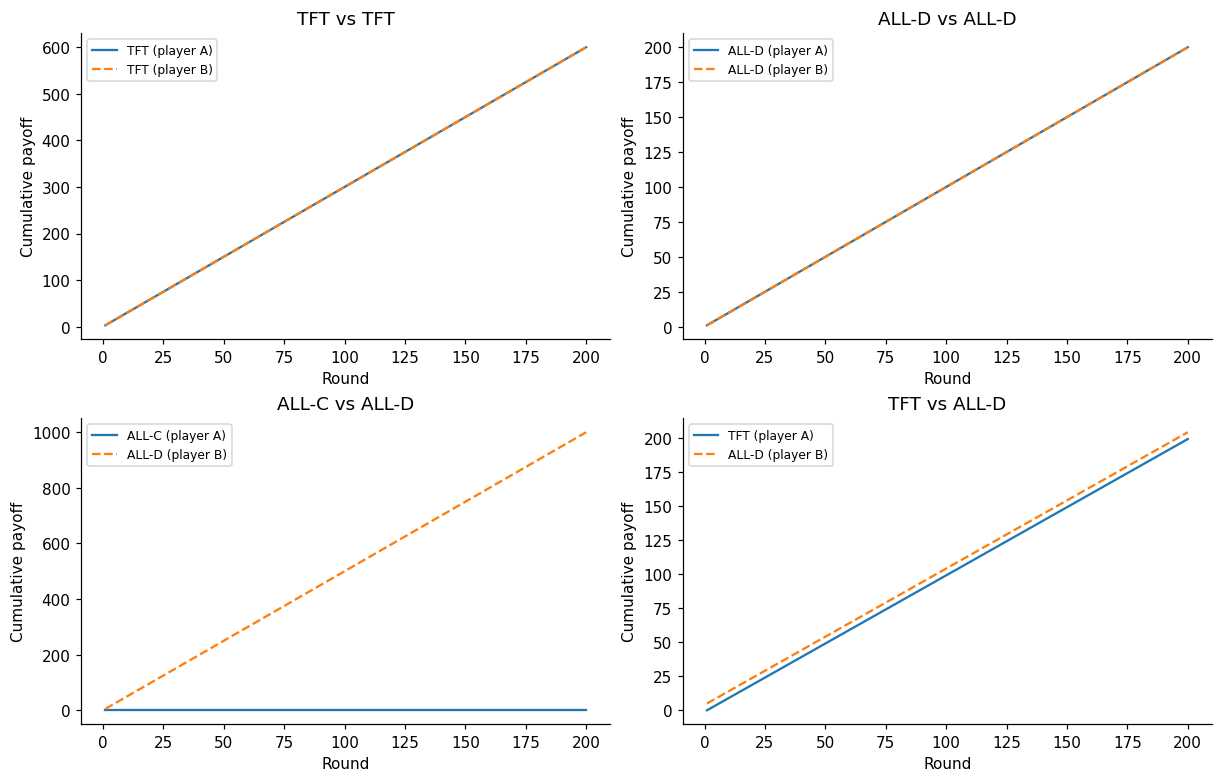

In [5]:
def repeated_pair(first, second, noise=0., generosity=GENEROSITY, rounds=ROUNDS,
                  repeats=REPEATS, seed=SEED):
    rng = random.Random(seed)
    runs = [play(first, second, rounds, noise, generosity, PAYOFFS,
                 rng.getrandbits(64)) for _ in range(repeats)]
    return np.stack([v[0] for v in runs]), np.stack([v[1] for v in runs])

pair_cases = [('TFT', 'TFT'), ('ALL-D', 'ALL-D'), ('ALL-C', 'ALL-D'), ('TFT', 'ALL-D')]
pair_results = {}
pair_rows = []
for first, second in pair_cases:
    scores, actions = repeated_pair(first, second)
    pair_results[first, second] = scores, actions
    totals = scores.sum(axis=1).mean(axis=0)
    pair_rows.append([first, second, f'{actions.mean():.2%}',
                      f'{scores[:, :, 0].mean():.3f}', f'{scores[:, :, 1].mean():.3f}',
                      f'{totals[0]:.2f}', f'{totals[1]:.2f}'])
show_table(['A', 'B', 'Cooperation', 'Mean payoff A', 'Mean payoff B', 'Total A', 'Total B'],
           pair_rows, 'pairwise_summary.csv')
fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
for ax, (first, second) in zip(axes.flat, pair_cases):
    scores, _ = pair_results[first, second]
    for i, name in enumerate((first, second)):
        ax.plot(np.arange(1, ROUNDS+1), scores.mean(axis=0).cumsum(axis=0)[:, i],
                label=f'{name} (player {"AB"[i]})', linestyle=['-', '--'][i])
    ax.set(title=f'{first} vs {second}', xlabel='Round', ylabel='Cumulative payoff')
    ax.legend(fontsize=8)
finish(fig, '01_pairwise_cumulative.png')

**Interpretation.** With the canonical matrix and $n$ noiseless rounds, TFT–TFT earns $3n$ per player; ALL-D–ALL-D earns $n$. ALL-C earns zero against ALL-D, which earns $5n$. TFT earns $n-1$ against ALL-D, which earns $n+4$. Retaliation therefore limits the exploiter’s lead to 5 total units rather than allowing it to grow by 5 every round. Repetition by itself does not rescue unconditional cooperators or make TFT beat ALL-D in their direct encounter.

## 6. Round-robin tournaments and metric definitions

Run two otherwise identical tournaments: no noise and the configured noise level (default 5%). The seed is fixed for reproducibility, and every repetition uses newly generated match seeds.

For strategy $i$, its per-round reward is the average across its $K-1$ opponents:
$$\bar\pi_i(t)=\frac{1}{K-1}\sum_{j\ne i}\pi_{ij}(t),\qquad U_i(t)=\sum_{\tau=1}^{t}\bar\pi_i(\tau).$$
System cooperation at round $t$ is the number of cooperative executed actions divided by $2\binom{K}{2}$. Curves average over repetitions. A final cumulative payoff is consequently a payoff **per opponent encounter over the horizon**, rather than the unnormalized total across four opponents.

For uncertainty, `SD` means the sample standard deviation of repetition-level means, and `SE = SD / sqrt(REPEATS)`. Mean ± 2 SE is an approximate uncertainty display, not a guaranteed confidence interval or a test of ranking differences.

In [6]:
scenarios = {'No noise': 0., f'{NOISE:.0%} action noise': NOISE}
results = {label: tournament(ROUNDS, REPEATS, noise, GENEROSITY, PAYOFFS, SEED)
           for label, noise in scenarios.items()}

def se(values):
    return values.std(axis=0, ddof=1) / np.sqrt(len(values))

def export_rounds(label, result):
    scores, cooperation, matrix = result
    stem = 'baseline' if label == 'No noise' else 'noise'
    avg = scores.mean(axis=0)
    with (OUT / f'{stem}_per_round.csv').open('w', newline='') as f:
        w = csv.writer(f)
        w.writerow(['round', 'cooperation'] + [f'{s}_payoff' for s in STRATEGIES] +
                   [f'{s}_cumulative' for s in STRATEGIES])
        for r in range(ROUNDS):
            w.writerow([r+1, cooperation[:, r].mean(), *avg[r], *avg.cumsum(axis=0)[r]])
    with (OUT / f'{stem}_pairwise.csv').open('w', newline='') as f:
        w = csv.writer(f)
        w.writerow(['row_player', *STRATEGIES])
        w.writerows([name, *['' if np.isnan(x) else x for x in row]]
                    for name, row in zip(STRATEGIES, matrix))
for label, result in results.items():
    export_rounds(label, result)
print('Both tournaments completed; round-level and pairwise CSVs exported.')

Both tournaments completed; round-level and pairwise CSVs exported.


### 6.1 System cooperation over time

Shading shows mean ± 2 SE across independent repetitions, clipped to [0,1]. It summarizes uncertainty in the mean curve, not the range of possible individual matches.

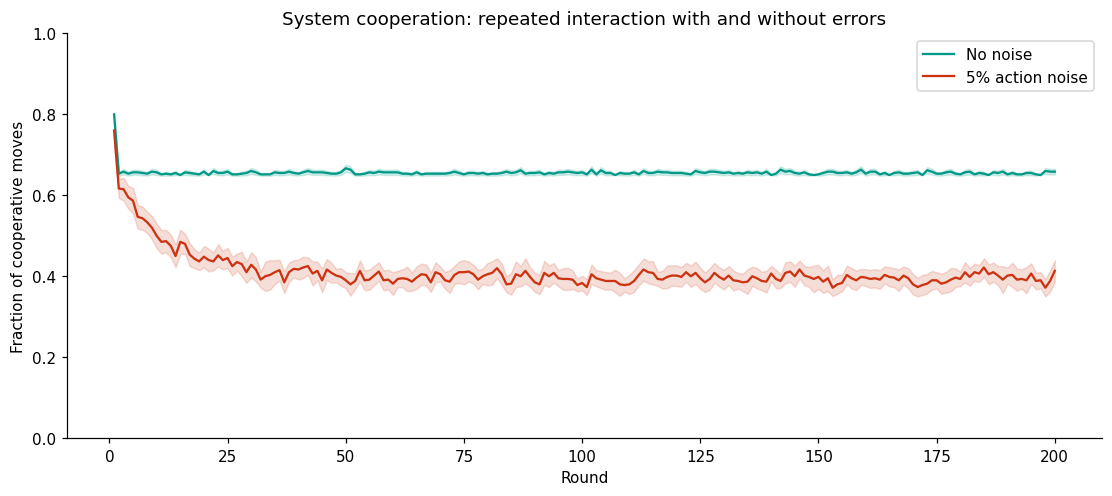

**Measured result:** overall cooperation is **65.59%** without noise and **41.15%** with 5% action noise, a change of **-24.44 percentage points**.

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.4), constrained_layout=True)
x = np.arange(1, ROUNDS+1)
for color, (label, (_, c, _)) in zip(['#009988', '#CC3311'], results.items()):
    mean, err = c.mean(axis=0), 2*se(c)
    ax.plot(x, mean, label=label, color=color)
    ax.fill_between(x, np.clip(mean-err, 0, 1), np.clip(mean+err, 0, 1), color=color, alpha=.16)
ax.set(xlabel='Round', ylabel='Fraction of cooperative moves', ylim=(0, 1),
       title='System cooperation: repeated interaction with and without errors')
ax.legend()
finish(fig, '02_system_cooperation.png')
base_c = next(iter(results.values()))[1].mean()
noise_c = list(results.values())[1][1].mean()
display(Markdown(f'**Measured result:** overall cooperation is **{base_c:.2%}** without noise and '
                 f'**{noise_c:.2%}** with {NOISE:.0%} action noise, a change of '
                 f'**{100*(noise_c-base_c):+.2f} percentage points**.'))

**Interpretation.** A decline is not an implementation failure: most strategies cooperate initially, then retaliate against ALL-D or accidental defections. These rules can sustain cooperation among compatible partners, but do not guarantee increasing cooperation in a mixed population. Fixed strategy proportions also mean this is not an evolutionary trajectory.

### 6.2 Per-round payoffs for every strategy

Per-round payoffs reveal transients and the reward level after retaliation begins. These are raw round-by-round means across repetitions, without smoothing.

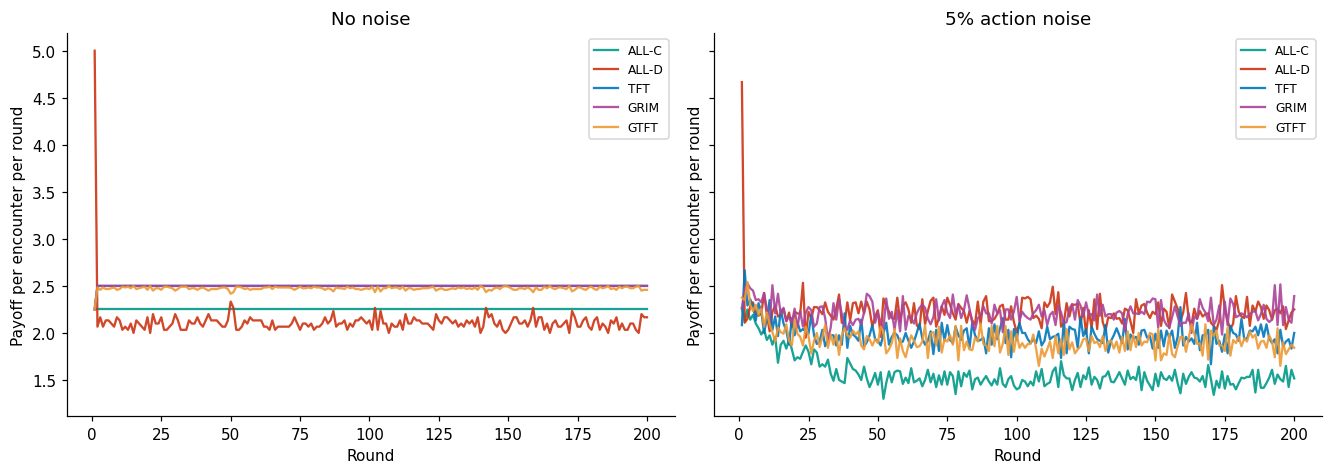

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True, sharey=True)
for ax, (label, (scores, _, _)) in zip(axes, results.items()):
    for i, name in enumerate(STRATEGIES):
        ax.plot(x, scores.mean(axis=0)[:, i], label=name, color=COLORS[i], alpha=.9)
    ax.set(title=label, xlabel='Round', ylabel='Payoff per encounter per round')
    ax.legend(fontsize=8)
finish(fig, '03_per_round_payoffs.png')

### 6.3 Cumulative payoffs for every strategy

A cumulative curve’s slope reflects its current reward rate. A rising cumulative payoff can coexist with falling cooperation, because mutual defection still earns a positive reward in the canonical matrix. Compare ranks and slopes rather than interpreting every increasing line as successful cooperation.

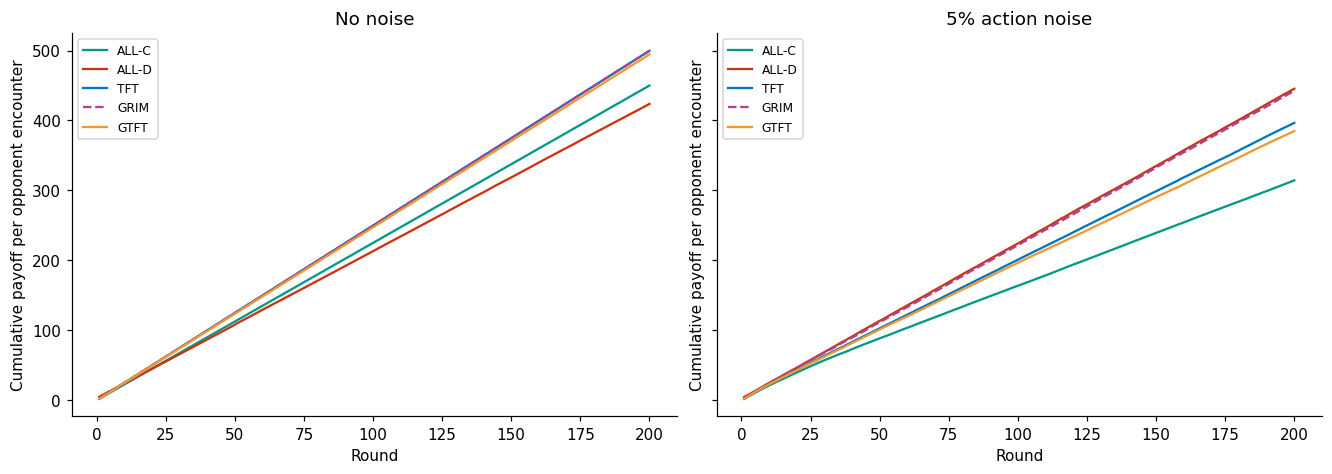

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True, sharey=True)
for ax, (label, (scores, _, _)) in zip(axes, results.items()):
    for i, name in enumerate(STRATEGIES):
        ax.plot(x, scores.mean(axis=0).cumsum(axis=0)[:, i], label=name,
                color=COLORS[i], linestyle='--' if name == 'GRIM' else '-')
    ax.set(title=label, xlabel='Round', ylabel='Cumulative payoff per opponent encounter')
    ax.legend(fontsize=8)
finish(fig, '04_cumulative_payoffs.png')

### 6.4 Pairwise payoff heatmaps

Read a cell as the **row strategy’s** payoff against the column strategy. Off-diagonal values need not be symmetric because exploitation benefits one player at the other’s expense. Dashes indicate excluded self-play. Both scenarios use the same color scale.

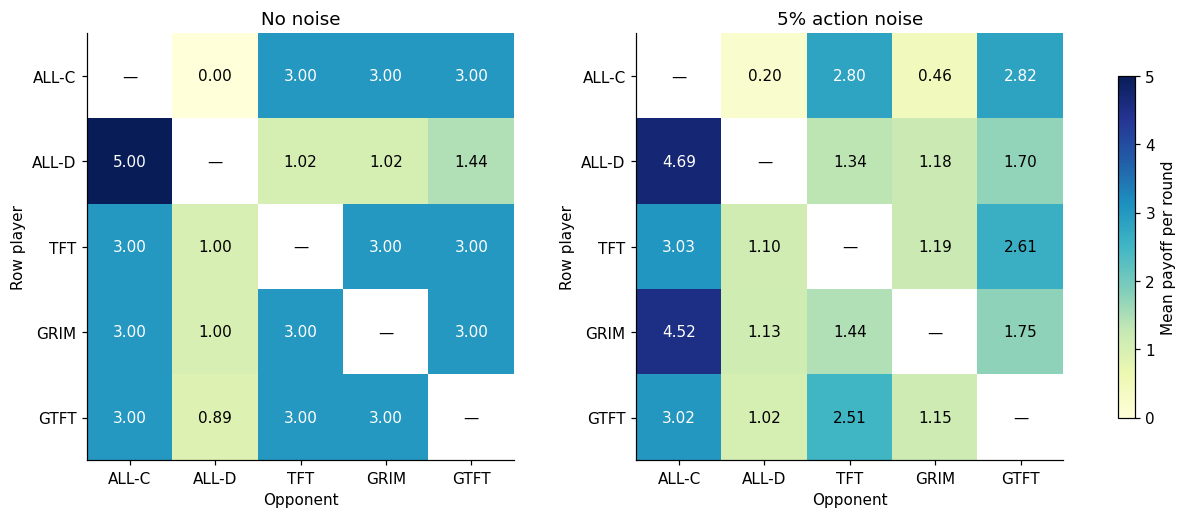

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), constrained_layout=True)
for ax, (label, (_, _, matrix)) in zip(axes, results.items()):
    im = ax.imshow(np.ma.masked_invalid(matrix), cmap='YlGnBu', vmin=S, vmax=T)
    ax.set(title=label, xticks=range(5), yticks=range(5),
           xticklabels=STRATEGIES, yticklabels=STRATEGIES, xlabel='Opponent', ylabel='Row player')
    for i in range(5):
        for j in range(5):
            value = matrix[i, j]
            ax.text(j, i, '—' if np.isnan(value) else f'{value:.2f}', ha='center', va='center',
                    color='white' if not np.isnan(value) and value > S+.55*(T-S) else 'black')
fig.colorbar(im, ax=axes, label='Mean payoff per round', shrink=.8)
finish(fig, '05_pairwise_heatmaps.png')

### 6.5 Numerical comparison and uncertainty

The table reports every strategy’s average and cumulative reward, and variability across independent repetition-level mean rewards. This makes the figure-based rankings auditable.

Scenario,Strategy,Mean payoff,SD,SE,Final cumulative
No noise,ALL-C,2.2500,0.0000,0.0000,450.000
No noise,ALL-D,2.1188,0.0212,0.0039,423.767
No noise,TFT,2.4988,0.0000,0.0000,499.750
No noise,GRIM,2.4988,0.0000,0.0000,499.750
No noise,GTFT,2.4728,0.0053,0.0010,494.558
5% action noise,ALL-C,1.5722,0.0570,0.0104,314.433
5% action noise,ALL-D,2.2273,0.0308,0.0056,445.450
5% action noise,TFT,1.9831,0.0597,0.0109,396.617
5% action noise,GRIM,2.2128,0.0528,0.0096,442.558
5% action noise,GTFT,1.9248,0.0523,0.0095,384.958


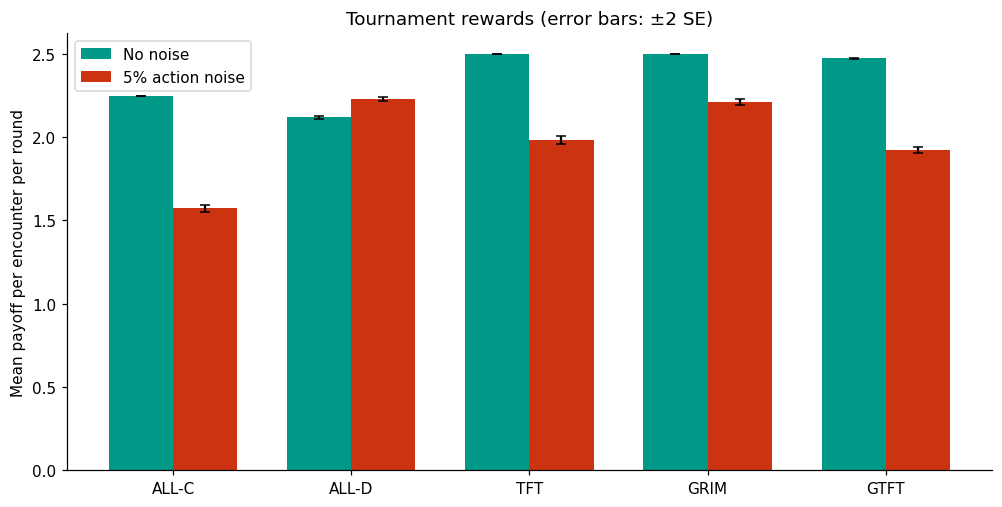

**No noise:** highest observed mean payoff = **2.499**, achieved by **TFT, GRIM**.

**5% action noise:** highest observed mean payoff = **2.227**, achieved by **ALL-D**.

In [11]:
summary_rows = []
for label, (scores, cooperation, _) in results.items():
    samples = scores.mean(axis=1)
    for i, name in enumerate(STRATEGIES):
        summary_rows.append([label, name, f'{samples[:, i].mean():.4f}',
                             f'{samples[:, i].std(ddof=1):.4f}',
                             f'{se(samples)[i]:.4f}',
                             f'{scores.sum(axis=1).mean(axis=0)[i]:.3f}'])
show_table(['Scenario', 'Strategy', 'Mean payoff', 'SD', 'SE', 'Final cumulative'],
           summary_rows, 'tournament_summary.csv')
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
positions = np.arange(len(STRATEGIES))
for offset, color, (label, (scores, _, _)) in zip([-.18, .18], ['#009988', '#CC3311'], results.items()):
    samples = scores.mean(axis=1)
    ax.bar(positions+offset, samples.mean(axis=0), width=.36, yerr=2*se(samples),
           capsize=3, label=label, color=color)
ax.set(xticks=positions, xticklabels=STRATEGIES, ylabel='Mean payoff per encounter per round',
       title='Tournament rewards (error bars: ±2 SE)')
ax.legend()
finish(fig, '06_strategy_reward_comparison.png')
for label, (scores, _, _) in results.items():
    means = scores.mean(axis=(0, 1))
    leaders = [STRATEGIES[i] for i in range(5) if np.isclose(means[i], means.max())]
    display(Markdown(f'**{label}:** highest observed mean payoff = **{means.max():.3f}**, '
                     f'achieved by **{", ".join(leaders)}**.'))

**Interpretation of the default experiment.** TFT and GRIM tie for the highest no-noise payoff. Both cooperate with responsive partners while limiting exploitation by ALL-D. With 5% action noise, ALL-D has the highest observed sample mean, narrowly above GRIM. This is a descriptive ranking; overlapping uncertainty displays and a single strategy composition do not establish a universal or statistically significant advantage. GRIM may obtain high payoffs by exploiting ALL-C after an error, so reward and cooperation must be interpreted separately. GTFT can repair mistakes but also gives ALL-D additional opportunities to exploit it. These statements describe the default configuration; use the generated tables to interpret changed settings.

## 7. Does forgiveness repair noisy reciprocal interaction?

Compare TFT–TFT and GTFT–GTFT under the same configured action-noise probability, horizon, and number of repetitions. This isolates encounters between identical reciprocal rules from the mixed tournament. Each repetition-level payoff averages the two player positions; uncertainty therefore treats a match, rather than its two correlated players, as the independent unit.

Pair,Overall cooperation,Mean player payoff,Payoff SD
TFT vs TFT,51.73%,2.2586,0.1967
GTFT vs GTFT,73.03%,2.6555,0.1192


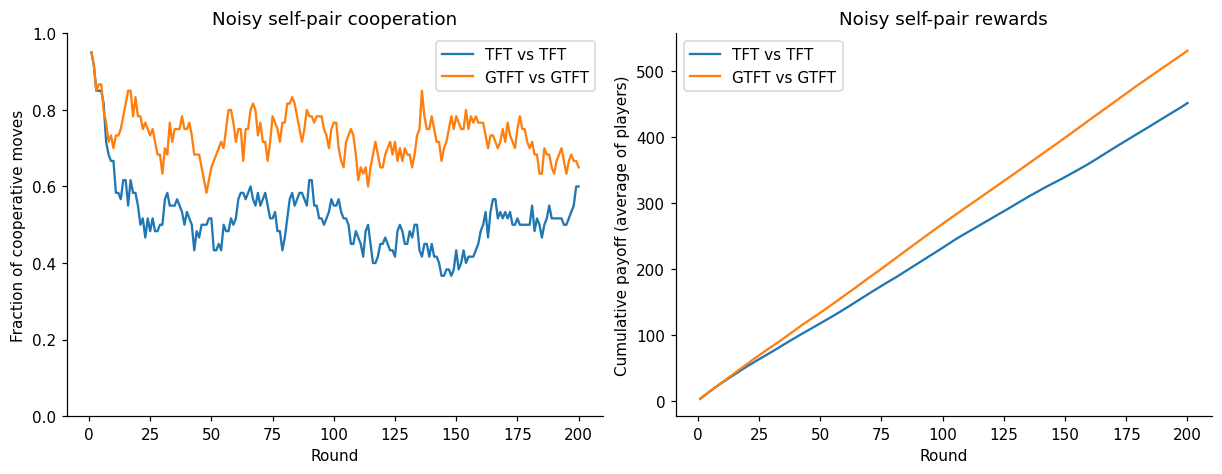

**Measured comparison:** TFT–TFT cooperation is **51.73%** and GTFT–GTFT cooperation is **73.03%**, a difference of **+21.31 percentage points**.

In [12]:
forgiving = {}
rows = []
for name in ('TFT', 'GTFT'):
    scores, actions = repeated_pair(name, name, noise=NOISE)
    forgiving[name] = scores, actions
    c_sample = actions.mean(axis=(1, 2))
    p_sample = scores.mean(axis=(1, 2))
    rows.append([name+' vs '+name, f'{c_sample.mean():.2%}',
                 f'{p_sample.mean():.4f}', f'{p_sample.std(ddof=1):.4f}'])
show_table(['Pair', 'Overall cooperation', 'Mean player payoff', 'Payoff SD'], rows, 'forgiveness_pairs.csv')
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
for name, (scores, actions) in forgiving.items():
    axes[0].plot(x, actions.mean(axis=(0, 2)), label=name+' vs '+name)
    axes[1].plot(x, scores.mean(axis=(0, 2)).cumsum(), label=name+' vs '+name)
axes[0].set(xlabel='Round', ylabel='Fraction of cooperative moves', ylim=(0,1), title='Noisy self-pair cooperation')
axes[1].set(xlabel='Round', ylabel='Cumulative payoff (average of players)', title='Noisy self-pair rewards')
for ax in axes: ax.legend()
finish(fig, '07_forgiveness_pairs.png')
tft_c = forgiving['TFT'][1].mean()
gtft_c = forgiving['GTFT'][1].mean()
display(Markdown(f'**Measured comparison:** TFT–TFT cooperation is **{tft_c:.2%}** and GTFT–GTFT '
                 f'cooperation is **{gtft_c:.2%}**, a difference of **{100*(gtft_c-tft_c):+.2f} percentage points**.'))

**Mechanism.** An accidental TFT defection may produce alternating retaliation. GTFT sometimes breaks that cycle by cooperating after a defection. GRIM cannot repair its intended cooperation once triggered. Improvement in a GTFT self-pair does not imply GTFT will win a tournament containing persistent defectors.

## 8. Sensitivity analysis: action-noise probability

A two-scenario comparison is extended across several error probabilities. All other settings remain fixed. Every point is a newly simulated round robin, using the same master seed for reproducibility. Shading indicates ±2 SE of repetition-level mean cooperation. This is a descriptive parameter scan, without multiple-comparison hypothesis tests.

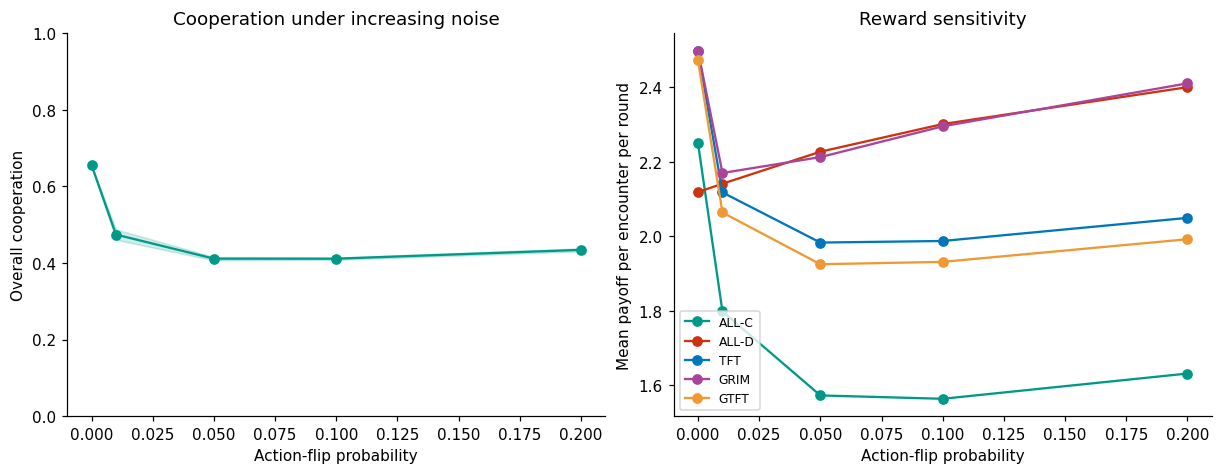

Noise,Cooperation,ALL-C mean payoff,ALL-D mean payoff,TFT mean payoff,GRIM mean payoff,GTFT mean payoff
0%,65.59%,2.2500,2.1188,2.4988,2.4988,2.4728
1%,47.44%,1.7979,2.1413,2.1179,2.1701,2.0639
5%,41.15%,1.5722,2.2272,1.9831,2.2128,1.9248
10%,41.14%,1.5631,2.3016,1.9873,2.2956,1.9312
20%,43.44%,1.6310,2.4008,2.0494,2.4110,1.9920


In [13]:
noise_grid = np.array([0., .01, .05, .10, .20])
noise_scan = [tournament(ROUNDS, REPEATS, float(e), GENEROSITY, PAYOFFS, SEED)
              for e in noise_grid]
coop_samples = np.array([c.mean(axis=1) for _, c, _ in noise_scan])
payoff_samples = np.array([s.mean(axis=1) for s, _, _ in noise_scan])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
means = coop_samples.mean(axis=1)
errors = 2*coop_samples.std(axis=1, ddof=1)/np.sqrt(REPEATS)
axes[0].plot(noise_grid, means, 'o-', color='#009988')
axes[0].fill_between(noise_grid, np.clip(means-errors,0,1), np.clip(means+errors,0,1), alpha=.18, color='#009988')
axes[0].set(xlabel='Action-flip probability', ylabel='Overall cooperation', ylim=(0,1), title='Cooperation under increasing noise')
for i, name in enumerate(STRATEGIES):
    axes[1].plot(noise_grid, payoff_samples.mean(axis=1)[:, i], 'o-', label=name, color=COLORS[i])
axes[1].set(xlabel='Action-flip probability', ylabel='Mean payoff per encounter per round', title='Reward sensitivity')
axes[1].legend(fontsize=8)
finish(fig, '08_noise_sensitivity.png')
show_table(['Noise', 'Cooperation', *[s+' mean payoff' for s in STRATEGIES]],
           [[f'{e:.0%}', f'{coop_samples[k].mean():.2%}',
             *[f'{v:.4f}' for v in payoff_samples[k].mean(axis=0)]] for k,e in enumerate(noise_grid)],
           'noise_sensitivity.csv')

**Interpretation.** Noise changes both retaliation and accidental cooperation, including for ALL-D. It can therefore change tournament rankings as well as cooperation. A monotonic effect for every strategy is not assumed. The scan concerns action-execution errors only; imperfect observation would be a different model.

## 9. Sensitivity analysis: forgiveness probability

GTFT with generosity 0 behaves like TFT; generosity 1 behaves like ALL-C. Compare GTFT self-pairs with its reward in the mixed tournament at each probability. This tests the tradeoff between repairing cooperation and becoming exploitable, rather than selecting a parameter solely because it produces a preferred conclusion.

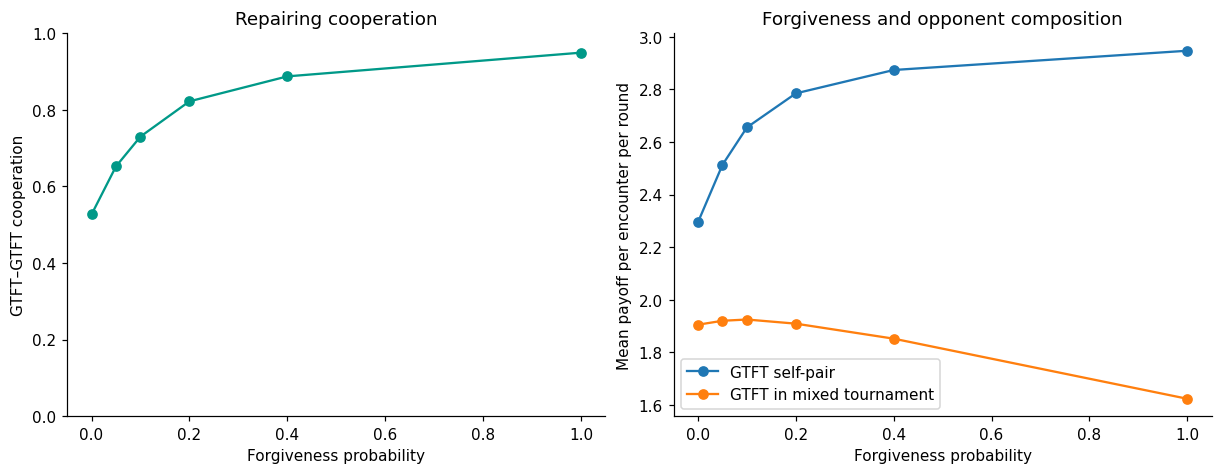

Generosity,Self-pair cooperation,Self-pair mean payoff,Mixed-tournament mean payoff
0.00,52.68%,2.2950,1.9050
0.05,65.25%,2.5132,1.9200
0.10,73.03%,2.6555,1.9248
0.20,82.23%,2.7850,1.9090
0.40,88.76%,2.8739,1.8519
1.00,94.95%,2.9472,1.6233


In [14]:
generosity_grid = [0., .05, .10, .20, .40, 1.]
forgive_rows = []
for generosity in generosity_grid:
    ps, pa = repeated_pair('GTFT', 'GTFT', noise=NOISE, generosity=generosity)
    ts, tc, _ = tournament(ROUNDS, REPEATS, NOISE, generosity, PAYOFFS, SEED)
    forgive_rows.append([generosity, pa.mean(), ps.mean(), ts[:, :, STRATEGIES.index('GTFT')].mean()])
arr = np.array(forgive_rows)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
axes[0].plot(arr[:,0], arr[:,1], 'o-', color='#009988')
axes[0].set(xlabel='Forgiveness probability', ylabel='GTFT–GTFT cooperation', ylim=(0,1), title='Repairing cooperation')
axes[1].plot(arr[:,0], arr[:,2], 'o-', label='GTFT self-pair')
axes[1].plot(arr[:,0], arr[:,3], 'o-', label='GTFT in mixed tournament')
axes[1].set(xlabel='Forgiveness probability', ylabel='Mean payoff per encounter per round', title='Forgiveness and opponent composition')
axes[1].legend()
finish(fig, '09_generosity_sensitivity.png')
show_table(['Generosity', 'Self-pair cooperation', 'Self-pair mean payoff', 'Mixed-tournament mean payoff'],
           [[f'{v[0]:.2f}', f'{v[1]:.2%}', f'{v[2]:.4f}', f'{v[3]:.4f}'] for v in arr],
           'generosity_sensitivity.csv')

**Interpretation.** More forgiveness can help compatible partners recover, but it also changes rewards against ALL-D and triggered GRIM. These objectives need not peak at the same probability. The grid is exploratory; it does not establish a globally optimal generosity parameter.

## 10. Horizon comparison: one-shot temptation and repeated retaliation

Use noiseless TFT–ALL-D to separate a short-term temptation from its long-run rate. With the configured matrix, TFT’s average reward is $[(n-1)P+S]/n$ and ALL-D’s is $[T+(n-1)P]/n$. The defector’s average advantage is $(T-S)/n$, although its total advantage remains $T-S$. TFT–TFT provides the cooperative benchmark $R$ per round.

This changes the number of rounds, not the players’ decision rules. It is not a model of finite-horizon backward induction or a proof that ALL-D loses every long game.

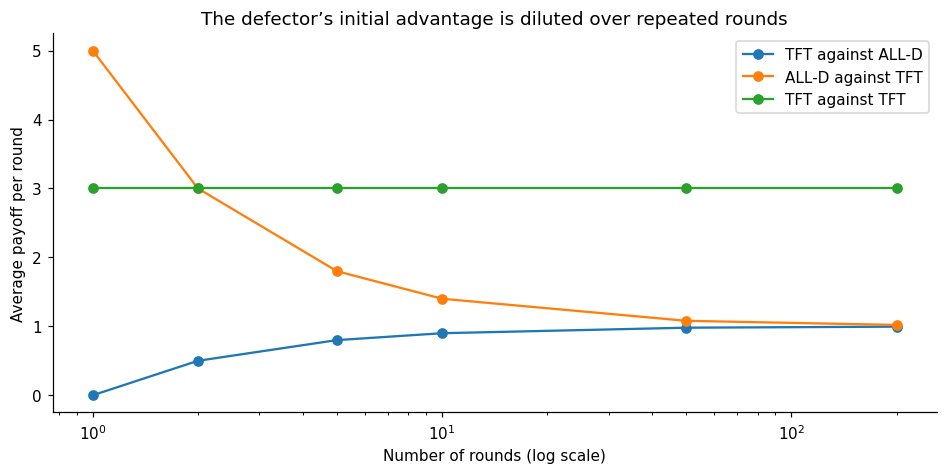

Rounds,TFT against ALL-D,ALL-D against TFT,TFT against TFT
1,0.0000,5.0000,3.0000
2,0.5000,3.0000,3.0000
5,0.8000,1.8000,3.0000
10,0.9000,1.4000,3.0000
50,0.9800,1.0800,3.0000
200,0.9950,1.0200,3.0000


In [15]:
horizons = [1, 2, 5, 10, 50, 200]
horizon_rows = []
for horizon in horizons:
    scores, _ = play('TFT', 'ALL-D', rounds=horizon, payoffs=PAYOFFS, seed=SEED)
    horizon_rows.append([horizon, scores[:,0].mean(), scores[:,1].mean(), R])
arr_h = np.array(horizon_rows)
fig, ax = plt.subplots(figsize=(8.5, 4.2), constrained_layout=True)
for i, label in enumerate(['TFT against ALL-D', 'ALL-D against TFT', 'TFT against TFT']):
    ax.plot(arr_h[:,0], arr_h[:,i+1], 'o-', label=label)
ax.set(xscale='log', xlabel='Number of rounds (log scale)', ylabel='Average payoff per round',
       title='The defector’s initial advantage is diluted over repeated rounds')
ax.legend()
finish(fig, '10_horizon_comparison.png')
show_table(['Rounds', 'TFT against ALL-D', 'ALL-D against TFT', 'TFT against TFT'],
           [[int(v[0]), *[f'{x:.4f}' for x in v[1:]]] for v in arr_h], 'horizon_comparison.csv')

## 11. Interactive simulation dashboard (optional extension)

This panel lets you change parameters and immediately inspect their consequences without editing the simulation code. **Run all preceding cells first**, then execute the panel cell. Choose **Pairwise game** or **Round-robin tournament**, adjust the controls, and click **Run simulation**. Pairwise mode supports identical strategies; round robin uses all five strategies and excludes self-play.

The panel uses the same `play` and `tournament` functions as the analysis. It shows per-round cooperation, per-round payoffs, cumulative payoffs, a pairwise payoff heatmap, and a numerical summary. The table distinguishes both player positions in self-pairs. Results represent the settings recorded above the figures; moving a control takes effect only after clicking Run.

Each successful run exports `interactive_overview.png`, `interactive_per_round.csv`, `interactive_pairwise.csv`, `interactive_summary.csv`, and `interactive_config.json` to `notebook_results/interactive/`. Those interactive files are replaced on the next successful run; the main analysis figures remain unchanged. The recorded seed makes a selected configuration reproducible.

**Installation:** `python -m pip install "ipywidgets>=8,<9"`. Use a running JupyterLab kernel to interact. GitHub displays saved plots but cannot execute buttons or sliders. If the controls do not appear after installation, restart JupyterLab and rerun the notebook.

In [16]:
import ipywidgets as widgets
import json
from IPython.display import clear_output

ui_mode = widgets.Dropdown(options=['Round-robin tournament', 'Pairwise game'], description='Mode:')
ui_a = widgets.Dropdown(options=STRATEGIES, value='TFT', description='Player A:')
ui_b = widgets.Dropdown(options=STRATEGIES, value='GTFT', description='Player B:')
ui_rounds = widgets.IntSlider(value=ROUNDS, min=1, max=max(1000, ROUNDS), step=1,
                             description='Rounds:', continuous_update=False)
ui_repeats = widgets.IntSlider(value=REPEATS, min=1, max=max(100, REPEATS), step=1,
                              description='Repeats:', continuous_update=False)
ui_noise = widgets.FloatSlider(value=NOISE, min=0, max=1, step=.01, description='Noise:',
                              readout_format='.2f', continuous_update=False)
ui_generosity = widgets.FloatSlider(value=GENEROSITY, min=0, max=1, step=.01,
                                   description='Forgiveness:', readout_format='.2f', continuous_update=False)
ui_seed = widgets.IntText(value=SEED, description='Seed:')
ui_payoffs = {name: widgets.FloatText(value=value, description=name+':',
                                    layout=widgets.Layout(width='150px'))
              for name, value in zip(('T','R','P','S'), (T,R,P,S))}
ui_run = widgets.Button(description='Run simulation', button_style='success', icon='play')
ui_status = widgets.HTML(value='Ready. Change settings, then click Run simulation.')
ui_output = widgets.Output()

def ui_sync_mode(change=None):
    for field in (ui_a, ui_b):
        field.disabled = ui_mode.value != 'Pairwise game'
ui_mode.observe(ui_sync_mode, names='value')
ui_sync_mode()

def dashboard_data(mode, first, second, rounds, repeats, noise, generosity, payoffs, seed):
    if mode == 'Round-robin tournament':
        scores, cooperation, matrix = tournament(rounds, repeats, noise, generosity, payoffs, seed)
        names = list(STRATEGIES)
    elif mode == 'Pairwise game':
        rng = random.Random(seed)
        runs = [play(first, second, rounds, noise, generosity, payoffs, rng.getrandbits(64))
                for _ in range(repeats)]
        scores = np.stack([run[0] for run in runs])
        cooperation = np.stack([run[1].mean(axis=1) for run in runs])
        matrix = np.array([[np.nan, scores[:,:,0].mean()],
                           [scores[:,:,1].mean(), np.nan]])
        names = [first+' (A)', second+' (B)']
    else:
        raise ValueError('Choose a supported mode.')
    return names, scores, cooperation, matrix

def dashboard_run(button=None):
    ui_run.disabled = True
    ui_status.value = 'Running…'
    try:
        # Validate before any figure or output file is changed.
        payoffs = Payoffs(**{name: field.value for name, field in ui_payoffs.items()})
        config = {'mode':ui_mode.value, 'player_a':ui_a.value, 'player_b':ui_b.value,
                  'rounds':ui_rounds.value, 'repeats':ui_repeats.value,
                  'noise':ui_noise.value, 'generosity':ui_generosity.value,
                  'seed':ui_seed.value, **{name: field.value for name,field in ui_payoffs.items()}}
        names, scores, cooperation, matrix = dashboard_data(
            config['mode'], config['player_a'], config['player_b'], config['rounds'],
            config['repeats'], config['noise'], config['generosity'], payoffs, config['seed'])
        avg = scores.mean(axis=0)
        samples = scores.mean(axis=1)
        sd = samples.std(axis=0, ddof=1) if config['repeats'] > 1 else None
        cumulative = avg.cumsum(axis=0)
        rounds = np.arange(1, config['rounds']+1)
        with ui_output:
            clear_output(wait=True)
            display(Markdown('**Executed settings:** '+json.dumps(config)))
            display(Markdown(f"**Overall cooperation: {cooperation.mean():.2%}.** "
                + ('Rewards are averaged over four opponents.' if config['mode']=='Round-robin tournament'
                   else 'Rewards are per player; positions A and B are kept separate.')))
            fig, axes = plt.subplots(2,2,figsize=(12,8),constrained_layout=True)
            axes[0,0].plot(rounds, cooperation.mean(axis=0), color='#009988')
            axes[0,0].set(title='System cooperation', xlabel='Round', ylabel='Cooperative move fraction', ylim=(0,1))
            for i, name in enumerate(names):
                style = '--' if i % 2 else '-'
                axes[0,1].plot(rounds,avg[:,i],label=name,linestyle=style,color=COLORS[i])
                axes[1,0].plot(rounds,cumulative[:,i],label=name,linestyle=style,color=COLORS[i])
            axes[0,1].set(title='Per-round payoff',xlabel='Round',ylabel='Payoff per encounter')
            axes[1,0].set(title='Cumulative payoff',xlabel='Round',ylabel='Cumulative payoff per encounter')
            axes[0,1].legend(fontsize=8)
            axes[1,0].legend(fontsize=8)
            im=axes[1,1].imshow(np.ma.masked_invalid(matrix),cmap='YlGnBu',vmin=payoffs.S,vmax=payoffs.T)
            axes[1,1].set(title='Row player mean payoff',xticks=range(len(names)),yticks=range(len(names)),
                          xticklabels=names,yticklabels=names,xlabel='Opponent',ylabel='Row player')
            for i in range(len(names)):
                for j in range(len(names)):
                    v=matrix[i,j]
                    axes[1,1].text(j,i,'—' if np.isnan(v) else f'{v:.2f}',ha='center',va='center',
                                  color='white' if np.isfinite(v) and v>payoffs.S+.55*(payoffs.T-payoffs.S) else 'black')
            fig.colorbar(im,ax=axes[1,1],shrink=.8)
            directory=OUT/'interactive'
            directory.mkdir(exist_ok=True)
            fig.savefig(directory/'interactive_overview.png',bbox_inches='tight',dpi=200)
            plt.show()
            plt.close(fig)
            rows=[[name,f'{samples[:,i].mean():.4f}',f'{cumulative[-1,i]:.3f}',
                   'N/A (one repetition)' if sd is None else f'{sd[i]:.4f}']
                  for i,name in enumerate(names)]
            show_table(['Strategy / player','Mean payoff','Final cumulative payoff','Replicate SD'],rows)
            with (directory/'interactive_summary.csv').open('w',newline='') as f:
                writer=csv.writer(f)
                writer.writerow(['player','mean_payoff','final_cumulative','replicate_sd'])
                writer.writerows([name,samples[:,i].mean(),cumulative[-1,i],None if sd is None else sd[i]]
                                 for i,name in enumerate(names))
            with (directory/'interactive_per_round.csv').open('w',newline='') as f:
                writer=csv.writer(f)
                writer.writerow(['round','cooperation']+[n+'_payoff' for n in names]+[n+'_cumulative' for n in names])
                writer.writerows([r+1,cooperation[:,r].mean(),*avg[r],*cumulative[r]]
                                 for r in range(config['rounds']))
            with (directory/'interactive_pairwise.csv').open('w',newline='') as f:
                writer=csv.writer(f)
                writer.writerow(['row_player',*names])
                writer.writerows([name,*['' if np.isnan(v) else v for v in row]] for name,row in zip(names,matrix))
            (directory/'interactive_config.json').write_text(json.dumps(config,indent=2)+'\n')
        ui_status.value = 'Completed. Results below match the executed settings; files saved in notebook_results/interactive/.'
    except ValueError as error:
        ui_status.value = 'Invalid settings: '+escape(str(error))+' Previous results remain unchanged.'
    except Exception as error:
        ui_status.value = 'Run failed: '+escape(str(error))
        raise
    finally:
        ui_run.disabled = False

ui_run.on_click(dashboard_run)
dashboard = widgets.VBox([
    widgets.HTML('<h3>Prisoner’s Dilemma — Interactive Lab</h3><p>Select settings and run a fresh experiment.</p>'),
    widgets.HBox([ui_mode,ui_a,ui_b]),
    widgets.HBox([ui_rounds,ui_repeats]),
    widgets.HBox([ui_noise,ui_generosity]),
    widgets.HBox(list(ui_payoffs.values())),
    widgets.HBox([ui_seed,ui_run]),ui_status,ui_output])
display(dashboard)
dashboard_run()


## 12. Conclusions and material for the written report

1. **Reciprocity sustains cooperation among compatible partners.** In noiseless TFT self-play, cooperation persists and earns the mutual-cooperation reward every round. Against ALL-D, retaliation limits continuing exploitation.
2. **Tournament success depends on the opponent mix.** The default no-noise tournament rewards TFT and GRIM, but this is not a universal winning-strategy result.
3. **Errors can undermine cooperation.** Action flips produce accidental defections, TFT retaliation cycles, and permanent GRIM triggers. A high cumulative payoff alone is not evidence of cooperation.
4. **Forgiveness is a tradeoff.** It can repair reciprocal encounters while permitting additional exploitation in a mixed tournament.
5. **“Emergence” has a limited meaning here.** Collective cooperation can be sustained by simple decentralized rules. The population does not learn or evolve, and cooperation need not increase over time. Demonstrating invasion or evolutionary spread would require an additional population-dynamics model.

### Suggested selection for a 1–2 page report

Use the model and strategy definitions; the main tournament summary table; **Figure 02** (cooperation over time); and **Figure 04 or 06** (payoff comparison). Include the noisy self-pair comparison if space permits. The remaining figures and CSVs provide supporting analysis. Write the report separately; this notebook contains evidence and explanations rather than replacing the assignment’s required short report.

### Limitations

Only five rules, equal encounter weights, a fixed horizon, perfect observation of executed moves, and independent action errors are modeled. Mean ±2 SE is approximate and is not a formal ranking test. The sensitivity scans cover a finite grid. No claims about universal optimality, real-world causal effects, or evolutionary stability follow from these experiments.

### Assignment coverage

| Requirement | Location |
|---|---|
| Runnable simulation with configurable payoffs and rounds | Sections 2–4; standalone implementation in this notebook |
| ALL-C, ALL-D, TFT, GRIM; recommended GTFT | Sections 3–4 |
| Pairwise and round-robin tournaments | Sections 5–6 |
| Per-round and cumulative payoff by strategy | Sections 6.2–6.5; exported round-level CSVs |
| Per-round system cooperation | Section 6.1 |
| Pairwise payoff matrices | Section 6.4; exported CSVs |
| Usage and reproducibility instructions | Section 1; fixed seeds and configuration |
| Optional noise extension and forgiveness comparison | Sections 7–9 |
| Interactive UI extension | Section 11: live controls, graphs and exports |
| Short report, 1–2 pages | To be written and uploaded separately by the student |

### Sources

- Ebubekir Koç, *The Concept of Cooperation*, IE49A Collective Computation, Fall 2026 — supplied course notes. Connections include reciprocal altruism, memory, and the shadow of future interaction.
- *Homework: Prisoner’s Dilemma Simulation* — supplied assignment specification.
- All numerical outputs and figures are generated by the executable code in this notebook; no external dataset is used.

In [17]:
print('Notebook completed successfully.')
print('Exported figure files:')
for path in sorted(OUT.glob('*.png')):
    print(' ', path.name)
print('Exported tables / time series:', len(list(OUT.glob('*.csv'))))

Notebook completed successfully.
Exported figure files:
  01_pairwise_cumulative.png
  02_system_cooperation.png
  03_per_round_payoffs.png
  04_cumulative_payoffs.png
  05_pairwise_heatmaps.png
  06_strategy_reward_comparison.png
  07_forgiveness_pairs.png
  08_noise_sensitivity.png
  09_generosity_sensitivity.png
  10_horizon_comparison.png
Exported tables / time series: 11
